# Working with the Nordic Gridded Climate Dataset

**Last updated:** 2026-09-30

[![binder](https://mybinder.org/badge.svg)](https://mybinder.org/v2/gh/ecmwf-training/jupyterbook-submodule-template/main?labpath=template-notebook.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ecmwf-training/jupyterbook-submodule-template/blob/main/template-notebook.ipynb)
[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecmwf-training/jupyterbook-submodule-template/blob/main/template-notebook.ipynb)

:::{note}
This notebook can be run on free online platforms, such as Binder, Kaggle and Colab, or they can be accessed from GitHub. The links to run this notebook in these environments are provided here, but please note they are not supported by ECMWF.
:::

## The Nordic Gridded Climate Dataset in brief

The Nordic Gridded Climate Dataset (NGCD) is a high resolution, observational, gridded dataset of daily mean, minimum and maximum temperatures and daily precipitation totals, covering Finland, Sweden and Norway. The time period covered begins in January 1961 and continues to the present. See the [product user guide](https://confluence.ecmwf.int/spaces/CKB/pages/278546882/Nordic+Gridded+Climate+Dataset+NGCD+Product+User+Guide+PUG) or the [algorithm theoretical basis document](https://confluence.ecmwf.int/spaces/CKB/pages/278546863/Nordic+Gridded+Climate+Dataset+NGCD+Algorithm+Theoretical+Basis+Document+ATBD) for more details.


## Learning objectives 🎯


### What to expect from this Jupyter notebook

This Jupyter notebook will help you to work with the Nordic Gridded Climate Dataset (NGCD), which can be obtained via [this page](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=overview). It will illustrate how to set up an API request and download data files from the Climate Data Store, as well as how to read the data, produce maps and get statistics.


### Target audience

- **Skill level:** Beginner to intermediate
- **Role or use case:** Researchers, students, educators, and other users of gridded climate observations
- **Domain background assumed:** Basic familiarity with Python and introductory data analysis

## Prepare your environment


### How to Access and Run the Notebook

This tutorial is provided as a Jupyter Notebook and can be executed either in a cloud-based environment or on a local machine. Three simple ways to run it locally are described below.

#### Option 1: VS Code

1. Install the [Python](https://marketplace.visualstudio.com/items?itemName=ms-python.python) and [Jupyter](https://marketplace.visualstudio.com/items?itemName=ms-toolsai.jupyter) extensions.
2. Open this repository folder in VS Code, then open this notebook.
3. Click **Select Kernel** (top right), then **Python Environments...** and **Create Python Environment**.
4. Choose **Venv** to create a `.venv` virtual environment in the current workspace. (If the installation was already done and a `.venv` exists, then choose to use it rather than recreate it).
5. If prompted to choose an interpreter, select for instance Python **3.12**.
6. When asked which dependencies to install, select **requirements.txt** and confirm.
7. Select the `.venv` environment as the notebook kernel if it is not already selected, then run the cells in order. If VS Code prompts you to install **ipykernel**, accept the installation.

#### Option 2: Jupyter Lab with uv

1. Install [uv](https://docs.astral.sh/uv/getting-started/installation/) if you don't already have it.
2. From a terminal in this repository, run:
   ```bash
   uv sync
   uv run jupyter lab
   ```
3. Jupyter Lab opens in your browser. Open this notebook, select the project's kernel, and run the cells.

#### Option 3: pip and requirements.txt

1. Create and activate a virtual environment:
   ```bash
   python -m venv .venv
   source .venv/bin/activate  # on Windows: .venv\Scripts\activate
   ```
2. Install the dependencies listed in `requirements.txt`, plus Jupyter Lab:
   ```bash
   pip install -r requirements.txt jupyterlab ipykernel
   ```
3. Launch Jupyter Lab and open the notebook:
   ```bash
   jupyter lab
   ```

### Import libraries and define some variables

Reading the downloaded NetCDF files requires the **netCDF4** backend in addition to xarray. It is listed in both `requirements.txt` and `pyproject.toml`. If your environment was created before this dependency was added, run `uv sync` (for the uv environment) or `python -m pip install -r requirements.txt` in a terminal with your notebook's environment activated. Then restart the notebook kernel and rerun the import cell. Make sure the selected kernel uses the environment where you installed the dependencies.


In [2]:
# Import your libraries here
import cdsapi
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from datetime import datetime
import cartopy.crs as ccrs
import glob
import os
import netCDF4  # Required backend for xarray's NetCDF reader.
from zipfile import ZipFile
from tempfile import TemporaryDirectory

# variable used further in the notebook
interpolation_type_mapping = {"kriging":"type_1", "stochastic Bayesian": "type_2"}
variables_mapping = {"precipitation": "RR",
                     "mean_temperature": "TG",
                     "maximum_temperature": "TX",
                     "minimum_temperature": "TN"}

### Setup credentials (optional)


If you have not setup your `~/.cdsapirc` file with your credentials, you can replace `None` with your credentials that can be found on the [how to api](https://cds.climate.copernicus.eu/how-to-api) page (you will need to log in to see your credentials).

In [2]:
# If you have already setup your .cdsapirc file you can leave this as None
cdsapi_key = None
cdsapi_url = None

### Maps for the temperature variables


#### Define your data request for temperature
The cell below illustrates how data files can be downloaded with an API request and how to choose the archive name (modify `zip_archive_name`). Note that a code snippet for the API request can be generated on the [this page](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=download) that is also used to manually download data files. As a fast example to run, we will download here 3 files, corresponding to the mean/minimum/maximum daily temperature for the first day of the dataset, that is 1st Januar 1961. We choose the dataset optained by kriging interpolation (type 1 files).

In [8]:
year = "1961"
month = "01"
day = "01"
version = "26_03"
dataset = "insitu-gridded-observations-nordic"
variables = [
        "mean_temperature",
        "minimum_temperature",
        "maximum_temperature",
    ]
interpolation = "kriging"
interpolation_type = interpolation_type_mapping[interpolation]
request = {
    "variable": variables,
    "spatial_interpolation_method": [
        interpolation_type
    ],
    "year": [year],
    "month": [month],
    "day": [day],
    "version": [version]
}

zip_archive_name = f"ngcd_all_var_{interpolation_type}_{year}{month}{day}.zip"
client = cdsapi.Client()
# Reuse the archive if it has already been downloaded.
if not os.path.exists(zip_archive_name):
    client.retrieve(dataset, request).download(zip_archive_name)

2026-10-15 20:58:34,343 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**


### Read the downloaded temperature data

Here we show how to read variables from the ZIP archive (downloaded in the previous cell) and how to load variables in memory and examine some metadata.
First check that the download of the ZIP archive is finished. It should contain four NetCDF files, with filenames built from the selected type, requested version, and date. Note that some of the variables used in this cell are defined in the previous cell. 


In [9]:
variable_data = {}
dato = f"{year}{month}{day}"
with ZipFile(zip_archive_name) as archive, TemporaryDirectory() as data_dir:
    for index_variable, variable in enumerate(variables):
        variable_name = variables_mapping[variable]
        ncfile = (
            f"NGCD_{variable_name}_{interpolation_type.replace('_', '')}"
            f"_version_{version.replace('_', '.')}_{dato}.nc"
        )
        if ncfile not in archive.namelist():
            raise FileNotFoundError(f"{ncfile} is not in {zip_archive_name}.")

        with xr.open_dataset(archive.extract(ncfile, data_dir), engine="netcdf4") as data:
            print(f"Data variables in file {ncfile}:")
            for name, data_variable in data.data_vars.items():
                print(
                    f"  {name}: {data_variable.attrs.get('long_name', '')} "
                    f"{data_variable.attrs.get('units', '')} "
                    f"(dimensions: {data_variable.dims})"
                )

            if index_variable == 0:
                print(f"Coordinates/time variables in file {ncfile}:")
                for name, coordinate in data.coords.items():
                    print(f"  {name} (coordinate): {coordinate.dims}")

            field = data[variable_name]

            if field.sizes["time"] != 1:
                raise ValueError(f"{ncfile}: expected exactly one time step, found {field.sizes['time']}.")

            variable_data[variable_name] = field.isel(time=0, drop=True).transpose("Y", "X").load()

            if index_variable == 0:
                mapping = data[field.attrs["grid_mapping"]]
                source_crs = ccrs.Projection(mapping.attrs["proj4"])
                print("SOme of the dataset attributes for variable {variable_name}):")
                for attribute in ["summary", "source", "project"]:
                    print(f"  {attribute}: {data.attrs[attribute]}")
                print(f"  Grid mapping: {mapping.attrs['grid_mapping_name']}")
                print(f"  Grid size: {data.sizes['X']} x-points, {data.sizes['Y']} y-points")
                print(f"  Latitude min-max: {np.nanmin(data['lat'].values):.2f}, {np.nanmax(data['lat'].values):.2f}")
                print(f"  Longitude min-max: {np.nanmin(data['lon'].values):.2f}, {np.nanmax(data['lon'].values):.2f}")

Data variables in file NGCD_TG_type1_version_26.03_19610101.nc:
  time_bounds:   (dimensions: ('time', 'nv'))
  TG: daily mean temperature K (dimensions: ('time', 'Y', 'X'))
  projection_laea:   (dimensions: ())
Coordinates/time variables in file NGCD_TG_type1_version_26.03_19610101.nc:
  Y (coordinate): ('Y',)
  X (coordinate): ('X',)
  time (coordinate): ('time',)
  lat (coordinate): ('Y', 'X')
  lon (coordinate): ('Y', 'X')
SOme of the dataset attributes for variable {variable_name}):
  summary: Nordic Gridded Climate Dataset (NGCD) daily precipitation dataset (variable RR). The aggregation time interval ranges from 0600 UTC previous day to 0600 UTC day reported as timestamp. NGCD is an observational gridded dataset and the input data comes from the Norwegian Meteorological Institute Climate Database and the European Climate Assessment & Dataset (ecad.eu). For more information on the datasets see https://github.com/metno/CASE. NGCD is based on the software https://github.com/metno/N

#### Plot daily temperature maps
The maps show daily mean/minimum/maximum temperature for the first day of the dataset (1st January 1961).

The display uses Lambert conformal conic (`+proj=lcc +lat_0=63 +lon_0=15 +lat_1=63 +lat_2=63 +no_defs +R=6.371e+06`). For precipitation, 1 kg/m² is equivalent to 1 mm of water.

Note: Cartopy downloads coastline and border data on first use, so an internet connection is needed for that first plot.

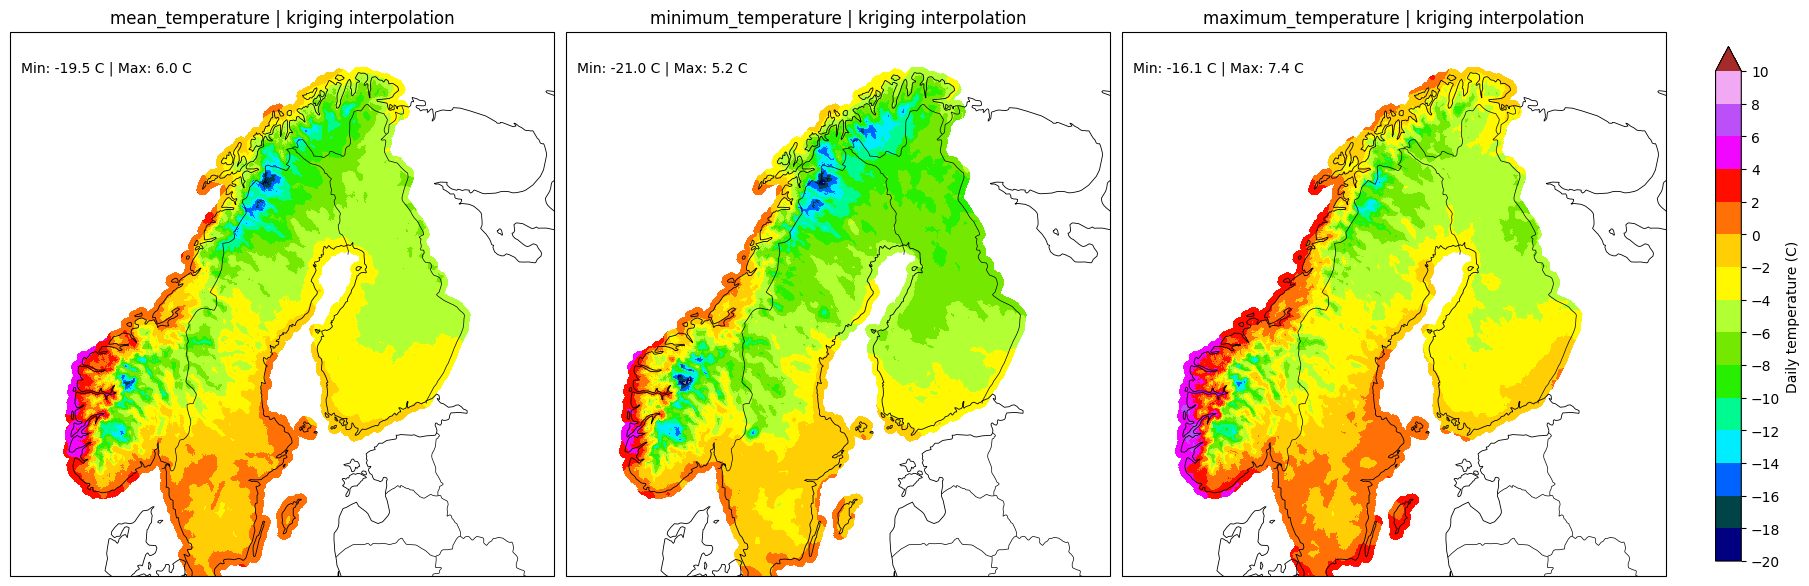

In [ ]:
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, ListedColormap
projection = ccrs.LambertConformal(
    central_longitude=15, central_latitude=63, standard_parallels=(63, 63),
    globe=ccrs.Globe(ellipse=None, semimajor_axis=6371000, semiminor_axis=6371000),
)

levels = np.arange(-20, 12, 2)
n_bins = len(levels) - 1  # (N-1) bins between the N boundaries
# choice of a colorbar that is not continuous to better see the color differences
base = plt.get_cmap("gist_ncar", n_bins + 1) # +1 so one excludes the white color from gist_ncar colorscale
cmap = ListedColormap(base(range(n_bins))) 
cmap.set_over("brown")
cmap.set_under("grey")
cmap.set_bad("white")
norm = BoundaryNorm(levels, cmap.N)

fig, axes = plt.subplots(
    1, len(variables), figsize=(6 * len(variables), 8),
    subplot_kw={"projection": projection}, squeeze=False,
    layout="constrained",
)
axes = axes.ravel()
for ax, variable, in zip(axes, variables):
    variable_name = variables_mapping[variable]
    # transform to C
    data = variable_data[variable_name] - 273.15 
    min_data = float(data.min())
    max_data = float(data.max())
    mesh = ax.pcolormesh(
        data.X, data.Y, data, transform=source_crs,
        cmap=cmap, norm=norm, shading="auto", rasterized=True,
    )
    ax.set_extent([3, 33, 55, 72], crs=ccrs.PlateCarree())
    ax.coastlines(resolution="50m", linewidth=0.6)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
    ax.set_title(f"{variable} | {interpolation} interpolation")
    ax.text(
        0.02, 0.92,
        f"Min: {min_data:.1f} C | Max: {max_data:.1f} C",
        transform=ax.transAxes, fontsize=10,
        verticalalignment="bottom", horizontalalignment="left",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 4},
    )

colorbar = fig.colorbar(
    mesh, ax=axes, orientation="vertical", boundaries=levels,
    ticks=levels, spacing="uniform", extend="max", shrink=0.65, pad=0.03,
)
colorbar.set_label("Daily temperature (C)")
plt.show()
fig.savefig(f"temperature_type{interpolation_type}_{dato}.png", dpi=300, bbox_inches="tight")

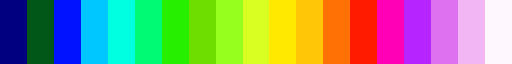

In [53]:
# from matplotlib.colors import BoundaryNorm, ListedColormap
# levels = np.arange(-20, 20, 2)
# base = plt.get_cmap("tab20c") # n_bins colors + 1 extra reserved for "over"
# cmap = ListedColormap(base([12, 13, 14, 15, 0, 1, 2, 3, 16, 17, 18, 19,  8, 9, 10, 11, 7, 6, 5, 4 ]))
# cmap.set_over("red")
# cmap.set_under("black")
# cmap.set_bad("white")
# norm = BoundaryNorm(levels, cmap.N)



# cmap = ListedColormap(base([12, 13, 14, 15, 0, 1, 2, 3, 16, 17, 18, 19,  8, 9, 10, 11, 7, 6, 5, 4 ]))
levels = np.arange(-20, 20, 2)
n_bins = len(levels) - 1  # 29 bins between the 30 boundaries
base = plt.get_cmap("gist_ncar", n_bins) # n_bins colors + 1 extra reserved for "over"
cmap = ListedColormap(base(range(n_bins)))
cmap.set_over("brown")
cmap.set_under("grey")
cmap.set_bad("white")
cmap

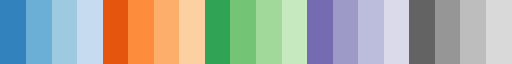

In [ ]:
cmap.

### Precipitation maps for Hans storm




#### Define your data request for precipitation
The cell below illustrates how data files can be downloaded with an API request and how to choose the archive name (modify `zip_archive_name`). Note that a code snippet for the API request can be generated on the [this page](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=download) that is also used to manually download data files. As a fast example to run, we will download here 6 files, corresponding to the daily precipitation variable for the kriging (type 1) interpolation approach and a stochastic Bayesian (type 2) interpolation for the period of the 7th to 9th August 2023. The selected dates are the days for [Hans storm](https://www.met.no/en/archive/the-extreme-weather-hans-is-bringing-an-extremely-large-amount-of-rain-over-southern-norway). These files will be placed in an zip archive file.

In [10]:
year = "2023"
month = "08"
days = ["07", "08", "09"]
version = "26_03"
dataset = "insitu-gridded-observations-nordic"
request = {
    "variable": ["precipitation"],
    "spatial_interpolation_method": [
        "type_1",
        "type_2"
    ],
    "year": [year],
    "month": [month],
    "day": days,
    "version": [version]
}

zip_archive_name = f"ngcd_RR_{year}{month}{days[0]}_{year}{month}{days[-1]}.zip"
# get a more readable name
for substring in ["[", "]", ",", "'", " "]:
    zip_archive_name = zip_archive_name.replace(substring, "")

client = cdsapi.Client()
# Reuse the archive if it has already been downloaded.
if not os.path.exists(zip_archive_name):
    client.retrieve(dataset, request).download(zip_archive_name)


2026-10-15 15:42:23,075 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-15 15:42:23,460 INFO Request ID is 00ddad7f-6fd5-4da4-8f7f-7067f81104e9
2026-10-15 15:42:23,538 INFO status has been updated to accepted
2026-10-15 15:42:47,745 INFO status has been updated to running
2026-10-15 15:43:42,172 INFO status has been updated to accepted
2026-10-15 15:44:20,701 INFO status has been updated to successful


### Read the downloaded data

Here we show how to read variables from the ZIP archive (downloaded in the previous cell) and how to load variables in memory and examine some metadata. Here we select the data obtained by stochastic Bayesian interpolation. 
First check that the download of the ZIP archive is finished. It should contain four NetCDF files, with filenames built from the selected type, requested version, and date. Note that some of the variables used in this cell are defined in the previous cell. The native grid projection is read once from the first NetCDF file, since all selected files share the same grid. 


In [ ]:
interpolation = "stochastic Bayesian" #"kriging"
interpolation_type = interpolation_type_mapping[interpolation]
precipitation_data = []
dates = [f"{year}{month}{day}" for day in days]
if not dates:
    raise ValueError("Choose at least one day in the request cell.")
with ZipFile(zip_archive_name) as archive, TemporaryDirectory() as data_dir:
    for index, dato in enumerate(dates):
        ncfile = f"NGCD_RR_{interpolation_type.replace("_","")}_version_{version.replace("_",".")}_{dato}.nc"
        if ncfile not in archive.namelist():
            raise FileNotFoundError(f"{ncfile} is not in {zip_archive_name}. Check the requested dates, version and interpolation type.")
        with xr.open_dataset(archive.extract(ncfile, data_dir), engine="netcdf4") as data:
            # The listing identifies RR as daily precipitation; data.RR accesses that variable.
            # Use the filename date: type-1 time units can be incorrect.
            if data.RR.sizes["time"] != 1:
                raise ValueError(f"{ncfile}: expected exactly one time step, found {data.RR.sizes['time']}.")
            # Load it into memory before the file closes and the temporary directory is removed.
            precipitation_data.append(data.RR.isel(time=0, drop=True).transpose("Y", "X").load())
            # Read the maping and show some attribute. Done only once this is the same for all the NGCD files            
            if index == 0:
                mapping = data[data.RR.attrs["grid_mapping"]]
                source_crs = ccrs.Projection(mapping.attrs["proj4"])

#### Plot daily precipitation maps
The maps show daily precipitation in the order of `days` (by default, 7th to 9th August 2023). All maps use the same stepped colour scale in millimetres; purple indicates totals above 50 mm.

The display uses Lambert conformal conic (`+proj=lcc +lat_0=63 +lon_0=15 +lat_1=63 +lat_2=63 +no_defs +R=6.371e+06`). For precipitation, 1 kg/m² is equivalent to 1 mm of water.

Note: Cartopy downloads coastline and border data on first use, so an internet connection is needed for that first plot.

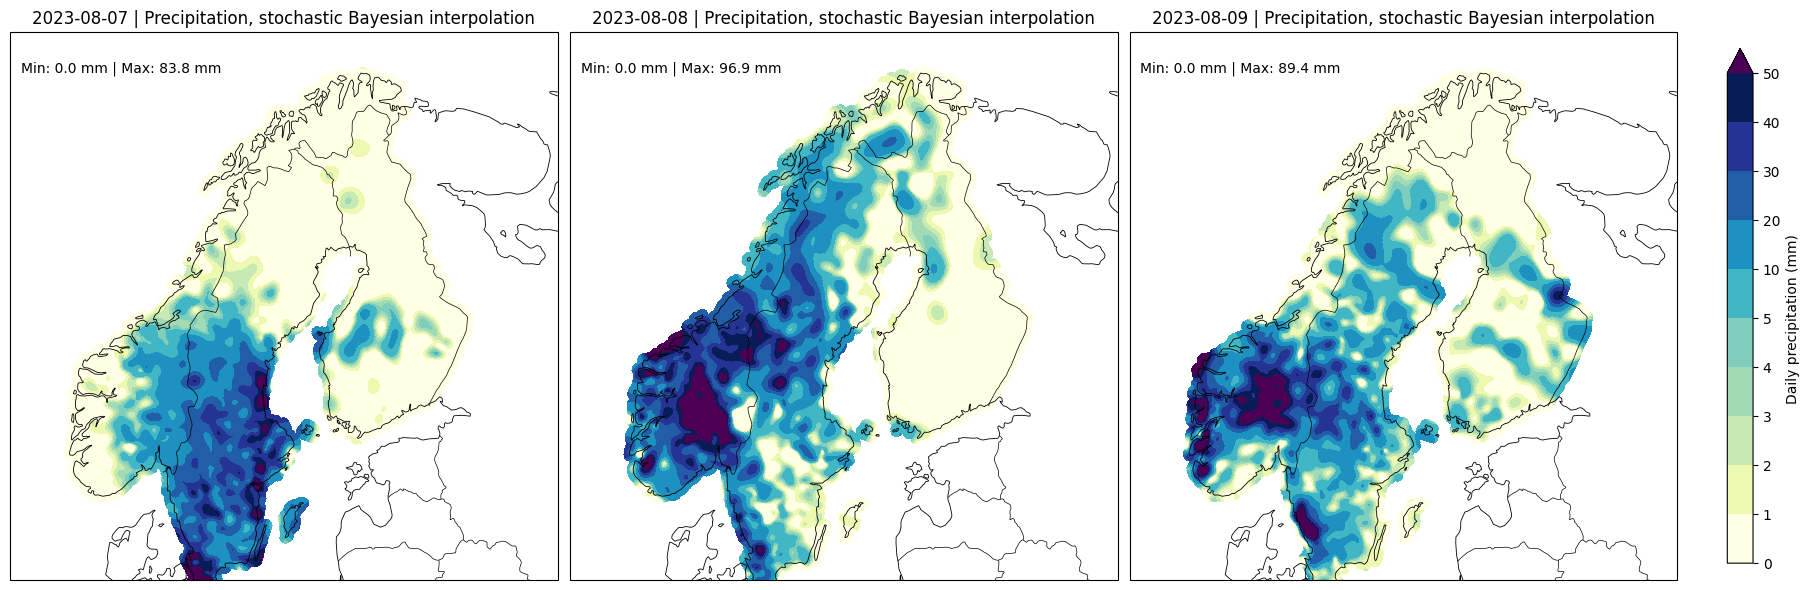

In [ ]:
from matplotlib.colors import BoundaryNorm, ListedColormap
import cartopy.feature as cfeature
projection = ccrs.LambertConformal(
    central_longitude=15, central_latitude=63, standard_parallels=(63, 63),
    globe=ccrs.Globe(ellipse=None, semimajor_axis=6371000, semiminor_axis=6371000),
)
levels = [0, 1, 2, 3, 4, 5, 10, 20, 30, 40, 50]

cmap = ListedColormap([
    "#ffffe5", "#edf8b1", "#c7e9b4", "#a1dab4", "#7fcdbb",
    "#41b6c4", "#1d91c0", "#225ea8", "#253494", "#081d58",
])
cmap.set_over("#4b0055")
cmap.set_bad("white")
norm = BoundaryNorm(levels, cmap.N)

fig, axes = plt.subplots(
    1, len(dates), figsize=(6 * len(dates), 8),
    subplot_kw={"projection": projection}, squeeze=False,
    layout="constrained",
)
axes = axes.ravel()
for ax, date, rain in zip(axes, dates, precipitation_data):
    min_precipitation = float(rain.min())
    max_precipitation = float(rain.max())
    mesh = ax.pcolormesh(
        rain.X, rain.Y, rain, transform=source_crs,
        cmap=cmap, norm=norm, shading="auto", rasterized=True,
    )
    ax.set_extent([3, 33, 55, 72], crs=ccrs.PlateCarree())
    ax.coastlines(resolution="50m", linewidth=0.6)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
    ax.set_title(f"{date} | Precipitation, {interpolation} interpolation")
    ax.text(
        0.02, 0.92,
        f"Min: {min_precipitation:.1f} mm | Max: {max_precipitation:.1f} mm",
        transform=ax.transAxes, fontsize=10,
        verticalalignment="bottom", horizontalalignment="left",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 4},
    )

colorbar = fig.colorbar(
    mesh, ax=axes, orientation="vertical", boundaries=levels,
    ticks=levels, spacing="uniform", extend="max", shrink=0.65, pad=0.03,
)
colorbar.set_label("Daily precipitation (mm)")
plt.show()
fig.savefig(f"precipitation_type{interpolation_type}_{dates[0]}_{dates[-1]}.png", dpi=300, bbox_inches="tight")

#### Plot 3-day accumulated precipitation map
We now compute the accumulated precipitation for the 3 days of the Hans storm, and plot a map of the total precipitation for the event.

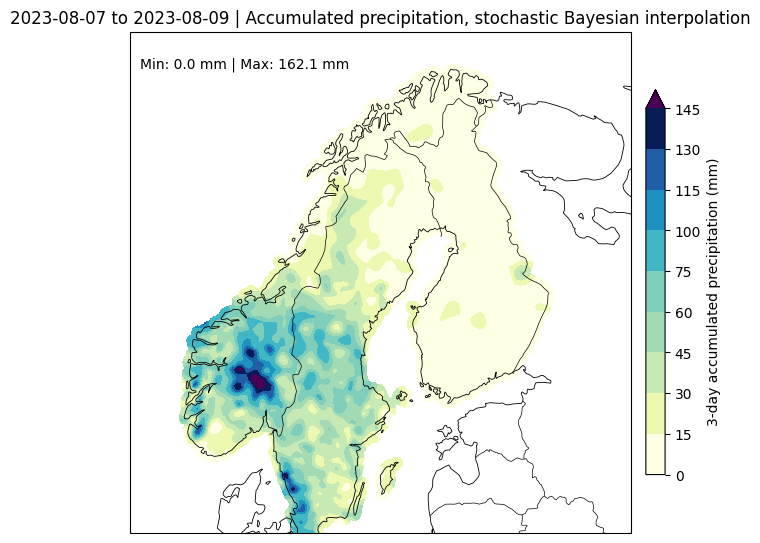

In [ ]:
levels = [0, 15, 30, 45, 60, 75, 100, 115, 130, 145]
norm = BoundaryNorm(levels, cmap.N)

# Sum the daily maps into a single 3-day accumulated total.
accumulated_precipitation = sum(precipitation_data)
min_precipitation = float(accumulated_precipitation.min())
max_precipitation = float(accumulated_precipitation.max())

fig, ax = plt.subplots(
    figsize=(6, 6),
    subplot_kw={"projection": projection},
    layout="constrained",
)
mesh = ax.pcolormesh(
    accumulated_precipitation.X, accumulated_precipitation.Y, accumulated_precipitation,
    transform=source_crs, cmap=cmap, norm=norm, shading="auto", rasterized=True,
)
ax.set_extent([3, 33, 55, 72], crs=ccrs.PlateCarree())
ax.coastlines(resolution="50m", linewidth=0.6)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
ax.set_title(f"{dates[0]} to {dates[-1]} | Accumulated precipitation, {interpolation} interpolation")

ax.text(
    0.02, 0.92,
    f"Min: {min_precipitation:.1f} mm | Max: {max_precipitation:.1f} mm",
    transform=ax.transAxes, fontsize=10,
    verticalalignment="bottom", horizontalalignment="left",
    bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 4},
)

colorbar = fig.colorbar(
    mesh, ax=ax, orientation="vertical", boundaries=levels,
    ticks=levels, spacing="uniform", extend="max", shrink=0.65, pad=0.03,
)
colorbar.set_label("3-day accumulated precipitation (mm)")
plt.show()
fig.savefig(f"precipitation_accumulated_type{interpolation_type}_{dates[0]}_{dates[-1]}.png", dpi=300, bbox_inches="tight")

#### 📖 Exercise: Try kriging interpolation

Repeat the precipitation maps for the same dates using **kriging (type 1)** instead of stochastic Bayesian interpolation (type 2).

1. Set `interpolation = "kriging"` in the data-loading cell.
2. Rerun the data-loading cell, then the plotting cell, keeping the same map extent and colour scale.
3. Compare the maps from the two interpolation methods. Where do the precipitation patterns and areas above 50 mm differ?

## Take home messages 📌


*In this section, summarise key take home messages.*

- *Key message 1*
- *Key message 2*
- *Key message 3*


## References

### Type 1 data

Tveito,O.E., Bjørdal,I., Skjelvåg,A.O., Aune,B. (2005) A GIS-based agro-ecoglogical decision system based on gridded climatology, Metoeorl.Appl., 12, 57-68, doi:10.1017/S1350482705001490

Tveito, O.E., E.J.Førland, R.Heino, I.Hanssen-Bauer, H.Alexandersson, B.Dahlström, A.Drebs, C.Kern-Hansen, T.Jónsson, E.Vaarby-Laursen and Y.Westman. (2000), Nordic Temperature Maps, DNMI Klima 9/00 KLIMA., Norwegian Meteorological Institute

### Type 2 data

Lussana, C., Tveito, O. E. and Uboldi, F. (2018), Three-dimensional spatial interpolation of 2 m temperature over Norway. Q.J.R. Meteorol. Soc.. doi:10.1002/qj.3208

Lussana, C., Saloranta, T., Skaugen, T., Magnusson, J., Tveito, O. E., and Andersen, J.: seNorge2 daily precipitation, an observational gridded dataset over Norway from 1957 to the present day, Earth Syst. Sci. Data, 10, 235-249, https://doi.org/10.5194/essd-10-235-2018, 2018.